# **Gaussian Naive Bayes from Scratch**
---
Member1 : Naglaa Mohamed Fathy || ID:20240626 .


Member2 : Habiba Khaled Hussien || ID:20242100 .




habooob eb2y nazly dol 
python -m pip install numpy matplotlib pandas scikit-learn
python -m pip install ipykernel jupyter

# *Task one: Data Preparation*
---

**Objective**: Load the Breast Cancer dataset and prepare it for training and testing our Gaussian Naive Bayes classifier.

*1.1-load data*

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

np.random.seed(42)

data = load_breast_cancer()
x = data.data
y= data.target
print("Dataset loaded successfully!")
print("Features(X):", x.shape)
print("Target(Y):", y.shape)
print("Classes Names:", data.target_names)

Matplotlib is building the font cache; this may take a moment.


Dataset loaded successfully!
Features(X): (569, 30)
Target(Y): (569,)
Classes Names: ['malignant' 'benign']


 *1.2-startification*

In [26]:
def train_test_split(x,y,test_size=0.2,seed=42):
    np.random.seed(seed)
    train_indices=[]
    test_indices=[]
    classes=np.unique(y)
    for cls in classes:
        class_indices=np.where(y==cls)[0]
        np.random.shuffle(class_indices)
        test_count = round(len(class_indices) * test_size)
        test_indices.extend(class_indices[:test_count])
        train_indices.extend(class_indices[test_count:])

    np.random.shuffle(train_indices)
    np.random.shuffle(test_indices)    
    X_train = x[train_indices]
    X_test = x[test_indices]

    y_train = y[train_indices]
    y_test = y[test_indices]
    
    return X_train, X_test, y_train, y_test

*1.3-test the spliting(20,80)*

In [29]:
X_train, X_test, y_train, y_test = train_test_split(x, y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


print("\nTraining class counts:")
print("Malignant:", np.sum(y_train == 0))
print("Benign:", np.sum(y_train == 1))

print("\nTesting class counts:")
print("Malignant:", np.sum(y_test == 0))
print("Benign:", np.sum(y_test == 1))

Training set: (456, 30)
Testing set: (113, 30)

Training class counts:
Malignant: 170
Benign: 286

Testing class counts:
Malignant: 42
Benign: 71


---

**1.4-Answering Question:**

**Does GNB need feature scaling?**

Gaussian Naive Bayes generally does not require feature scaling because it calculates a separate mean and variance for each feature. However, we should test both versions and compare their accuracywith and without standardization to verify whether scaling makes a difference in our dataset.

*1)Feature Scaling Comparison*

In [30]:

mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
#no divide zero
std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled training feature means (first 5):",
      np.mean(X_train_scaled, axis=0)[:5])


model_original = GNBayes()
model_original.fit(X_train, y_train)


model_scaled = GNBayes()
model_scaled.fit(X_train_scaled, y_train)

print("Original model trained successfully.")
print("Scaled model trained successfully.")

Original training shape: (456, 30)
Scaled training shape: (456, 30)
Scaled training feature means (first 5): [-4.36590335e-15 -1.54408650e-15  4.38343319e-15  5.88223427e-16
 -7.60113220e-16]
Original model trained successfully.
Scaled model trained successfully.


# m7tageen el predict hena mtnse4 

---

# *Task Two: Implement GaussianNaiveBayes*
---

*2.1-Prior probability:*

how likely a class is before examining any features.

**formula :**

P(c)=Number of samples in class / Total number of samples


In [18]:
classes=np.unique(y_train)
class_prior={}
for cls in classes:
    class_count=np.sum(y_train==cls)
    class_prior[cls]= class_count/len(y_train)
print("Class_priors: ")   
print(class_prior) 

Class_priors: 
{np.int64(0): np.float64(0.37280701754385964), np.int64(1): np.float64(0.6271929824561403)}


---
**2.2-Means and Variances:**

*Mean (theta)*: the average value of a feature among samples belonging to a particular class

*Variance (var)* : Variance measures how spread out the values are around their mean.

In [19]:
theta=[]
var=[]
for c in classes:
    x_class=X_train[y_train==c]
    class_mean=np.mean(x_class,axis=0)
    class_var=np.var(x_class,axis=0)
    theta.append(class_mean)
    var.append(class_var)
theta=np.array(theta)
var=np.array(var)
print("Means shape:", theta.shape)
print("Variances shape:",var.shape)
    


Means shape: (2, 30)
Variances shape: (2, 30)


*inspect the first five feature means for each class*

In [20]:
print("Malignant means (first 5 features):")
print(theta[0][:5])

print("\nBenign means (first 5 features):")
print(theta[1][:5])

Malignant means (first 5 features):
[1.73296471e+01 2.13794706e+01 1.14485765e+02 9.65445882e+02
 1.03343294e-01]

Benign means (first 5 features):
[1.20680594e+01 1.80081119e+01 7.75604895e+01 4.57037762e+02
 9.28576224e-02]


---
**2.3- Variance Smoothing**

Formula : var_smotthing x max variance of X


In [22]:
var_smoothing =1e-9
max_var=var_smoothing*np.var(X_train,axis=0).max()
var=var+max_var
print("largest variance across all features", max_var)
print("Minimum variance after smoothing:", np.min(var))

largest variance across all features 0.0003165948974868709
Minimum variance after smoothing: 0.0006375332573590705


---
**2.4-Implementing the GaussianNaiveBayes Class— Parameter Estimation**

In [14]:
class GNBayes:
    def __init__(self,var_smoothing=1e-9):
        self.var_smoothing=var_smoothing
    
    def fit(self,x,y):
        self.classes=np.unique(y)
        self.class_prior=[]
        self.theta=[]
        self.var=[]

        for cl in self.classes:
            x_class=x[y==cl]
            self.class_prior.append(len(x_class)/len(x))
            self.theta.append(np.mean(x_class, axis=0))
            self.var.append(np.var(x_class,axis=0))

        self.class_prior=np.array(self.class_prior)
        self.theta=np.array(self.theta)
        self.var=np.array(self.var)

        max_var = self.var_smoothing * np.var(x, axis=0).max()
        self.var+=max_var
        self.max_var=max_var

        return self
    
    def _log_gaussian(self, x):
        return -0.5 * np.log(2 * np.pi * self.var) - \
               ((x - self.theta) ** 2) / (2 * self.var)
               
    
    def _log_posterior(self, x):
        log_likelihood = self._log_gaussian(x).sum(axis=1)
        return np.log(self.class_prior) + log_likelihood
    
    
    def predict(self, X):
        predictions = []

        for x in X:
            scores = self._log_posterior(x)
            predicted_class = self.classes[np.argmax(scores)]
            predictions.append(predicted_class)

        return np.array(predictions) 
    
    def predict_proba(self, X):
        probabilities = []

        for x in X:
            scores = self._log_posterior(x)
            scores -= np.max(scores) 
            exp_scores = np.exp(scores)
            
            probabilities.append(exp_scores / exp_scores.sum())

        return np.array(probabilities)    
    
    probabilities = tiny_model.predict_proba(x_tiny)
    print(probabilities)


[[1.00000000e+00 3.97896362e-12]
 [9.99999993e-01 7.19413438e-09]
 [9.99986993e-01 1.30071300e-05]
 [1.30071300e-05 9.99986993e-01]
 [7.19413438e-09 9.99999993e-01]
 [3.97896362e-12 1.00000000e+00]]


In [9]:
predictions = tiny_model.predict(x_tiny)
print(predictions)

[0 0 0 1 1 1]


---

**2.5-Sanity test**

In [13]:
import numpy as np
x_tiny = np.array([
    [1.0],
    [2.0],
    [3.0],
    [6.0],
    [7.0],
    [8.0]
])

y_tiny = np.array([0, 0, 0, 1, 1, 1])

tiny_model = GNBayes()
tiny_model.fit(x_tiny, y_tiny)

print("Classes:", tiny_model.classes)
print("Class priors:", tiny_model.class_prior)
print("Means:", tiny_model.theta)
print("Variances:", tiny_model.var)

Classes: [0 1]
Class priors: [0.5 0.5]
Means: [[2.]
 [7.]]
Variances: [[0.66666667]
 [0.66666667]]


In [ ]:
import math

x_value = 3
mean = 2
variance = 2 / 3

probability = (1 / math.sqrt(2 * math.pi * variance)) * math.exp(
    -((x_value - mean) ** 2) / (2 * variance)
)

print("Gaussian probability density:", probability)

probabilities = []

for i in range(len(tiny_model.classes)):
    mean = tiny_model.theta[i, 0]
    variance = tiny_model.var[i, 0]

    density = (1 / np.sqrt(2 * np.pi * variance)) * np.exp(
        -((x_value - mean) ** 2) / (2 * variance)
    )

    posterior = tiny_model.class_prior[i] * density
    probabilities.append(posterior)

print("Unnormalized posteriors:", probabilities)

Gaussian probability density: 0.2307994842081829
Unnormalized posteriors: [np.float64(0.11541343052401316), np.float64(1.5092547887303489e-06)]


normalize the probability

In [ ]:
probabilities = np.array(probabilities)

normalized = probabilities / np.sum(probabilities)

print("Normalized probabilities:", normalized)
print("Predicted class:", tiny_model.classes[np.argmax(normalized)])

Normalized probabilities: [9.99986923e-01 1.30767714e-05]
Predicted class: 0


---

# *Task three : Evaluation Metrics from Scratch*
---

 **3.1-Accuracy**

In [17]:
def accuracy(y_true, y_pred):
    correct = np.sum(y_true == y_pred)
    total = len(y_true)
    return correct / total

y_true = np.array([0, 0, 1, 1, 1])
y_pred = np.array([0, 1, 1, 1, 0])
print("Accuracy:", accuracy(y_true, y_pred))

Accuracy: 0.6


---
**3.2-Confusion Matrix**

In [19]:
def confusion_matrix(y_true, y_pred):
    classes=np.unique(np.concatenate((y_true, y_pred)))
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    
    for i, actual in enumerate(classes):
        for j, predicted in enumerate(classes):
            matrix[i , j] = np.sum((y_true == actual) &(y_pred == predicted))
                  
    return matrix
print("Confusion Matrix:", confusion_matrix(y_true, y_pred))

Confusion Matrix: [[1 1]
 [1 2]]


---
**3.3-Precision, Recall and F1-Score**

In [20]:
def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    precision = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fp = np.sum(cm[:,i])-tp
        if tp + fp == 0:
            precision.append(0.0)
        else:
            precision.append(tp / (tp + fp))
    return np.array(precision)
print("Precision Score:", precision_score(y_true, y_pred))

Precision Score: [0.5        0.66666667]


In [21]:
def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    recall = []
    for i in range(len(cm)):
        tp = cm[i,i]
        fn= np.sum(cm[i,:])-tp
        
        if tp + fn ==0:
            recall.append(0.0)
        else:
            recall.append(tp / (tp + fn))
    return np.array(recall)
print("Recall Score:", recall_score(y_true, y_pred))

Recall Score: [0.5        0.66666667]


In [22]:
def f1_score(y_true,y_pred):
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1=[]
    for i in range(len(precision)):
        if precision[i] + recall[i] == 0:
            f1.append(0.0)
        else:
            f1.append(2 * (precision[i] * recall[i]) / (precision[i] + recall[i]))
    return np.array(f1)

print("F1 Score:", f1_score(y_true, y_pred))

F1 Score: [0.5        0.66666667]


---
**3.4-Macro Average**

In [23]:
def macro_average(scores):
    return np.mean(scores)

print("Macro Average Precision:", macro_average(precision_score(y_true, y_pred)))
print("Macro Average Recall:", macro_average(recall_score(y_true, y_pred)))
print("Macro Average F1 Score:", macro_average(f1_score(y_true, y_pred)))

Macro Average Precision: 0.5833333333333333
Macro Average Recall: 0.5833333333333333
Macro Average F1 Score: 0.5833333333333333


---
**3.5-Testing Gaussian Naive Bayes on Breast Cancer Dataset**

In [31]:
gnb_model = GNBayes()
gnb_model.fit(X_train, y_train)
y_pred = gnb_model.predict(X_test)

In [33]:
print("Accuracy:", accuracy(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print("Macro Precision:", macro_average(precision_score(y_test, y_pred)))
print("Macro Recall:", macro_average(recall_score(y_test, y_pred)))
print("Macro F1-Score:", macro_average(f1_score(y_test, y_pred)))

Accuracy: 0.9380530973451328
Confusion Matrix:
[[40  2]
 [ 5 66]]
Precision: [0.88888889 0.97058824]
Recall: [0.95238095 0.92957746]
F1-Score: [0.91954023 0.94964029]
Macro Precision: 0.9297385620915033
Macro Recall: 0.9409792085848423
Macro F1-Score: 0.9345902588274209


---

# *Task Four : Experiments*
---

Investigate what happens when we duplicate one strongly informative feature in our Breast Cancer dataset.

*4.1) strongly informative feature :*

In [ ]:
class_0 = X_train[y_train == 0]
class_1 = X_train[y_train == 1]

mean_difference = np.abs( np.mean(class_0, axis=0) - np.mean(class_1, axis=0))
feature_std = np.std(X_train, axis=0)
separation = mean_difference / feature_std
best_feature_index = np.argmax(separation)
print("Feature index:", best_feature_index)
print("Feature name:", data.feature_names[best_feature_index])
print("Separation score:", separation[best_feature_index])

Feature index: 27
Feature name: worst concave points
Separation score: 1.6170604395362143


---
*4.2) duplicated datasets :*

In [ ]:
copies_list = [1, 3, 5, 10]

duplicated_datasets = {}

for n in copies_list:
    x_train_dup = np.column_stack([X_train] + [X_train[:, best_feature_index]] * (n - 1))
    x_test_dup = np.column_stack([X_test] + [X_test[:, best_feature_index]] * (n - 1))
    duplicated_datasets[n] = (x_train_dup, x_test_dup)

    print(f"{n} copies:")
    print("Training shape:", x_train_dup.shape)
    print("Testing shape:", x_test_dup.shape)

1 copies:
Training shape: (456, 30)
Testing shape: (113, 30)
3 copies:
Training shape: (456, 32)
Testing shape: (113, 32)
5 copies:
Training shape: (456, 34)
Testing shape: (113, 34)
10 copies:
Training shape: (456, 39)
Testing shape: (113, 39)


---
*4.3) Train Models :*

In [ ]:
models = {}

for n in copies_list:
    X_train_dup, X_test_dup = duplicated_datasets[n]

    model = GNBayes()
    model.fit(X_train_dup, y_train)

    models[n] = model

    print(f"Model with {n} copies trained successfully.")

Model with 1 copies trained successfully.
Model with 3 copies trained successfully.
Model with 5 copies trained successfully.
Model with 10 copies trained successfully.


Each model learns its own means and variances based on the number of duplicated features.

---
*4.4) Experiment :*

In [ ]:
results = {
    "copies": [],
    "accuracy": [],
    "avg_confidence": []
}

for n in copies_list:
    results["copies"].append(n)

print(results)

---

# *Task Five : Visualization*
---

**5.1-Gaussian Distribution for Each Feature**

In [34]:
import matplotlib.pyplot as plt

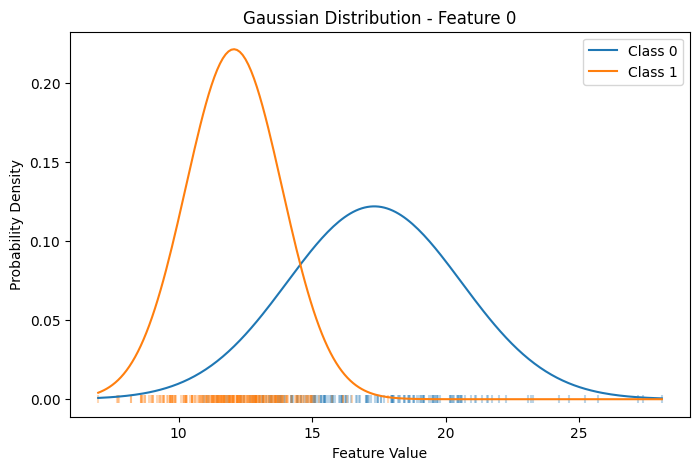

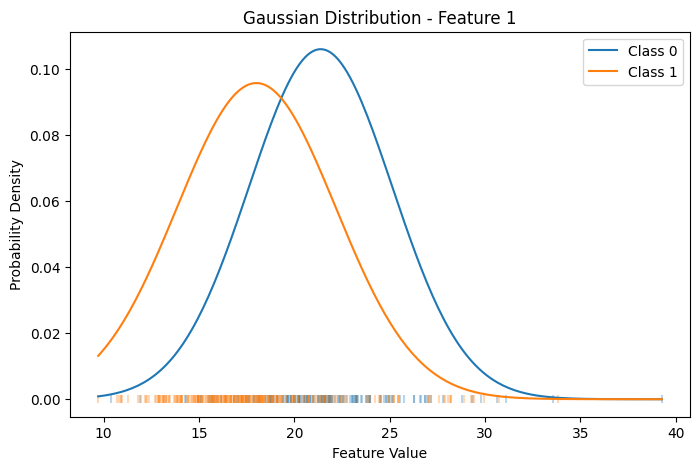

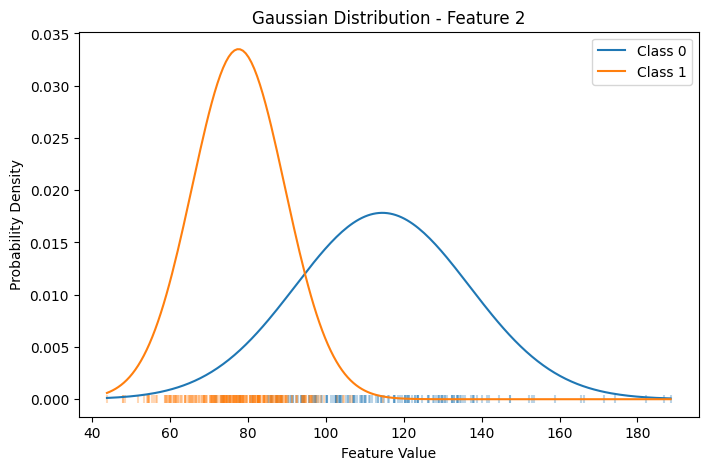

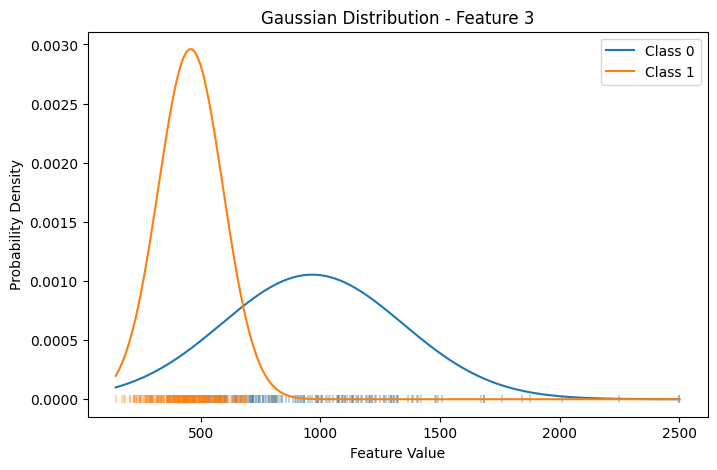

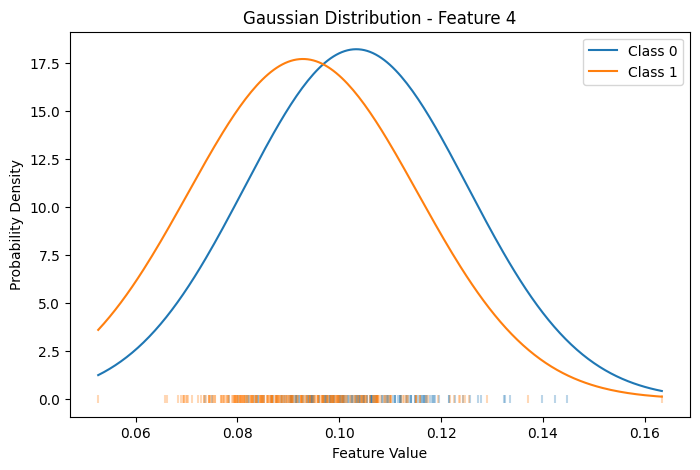

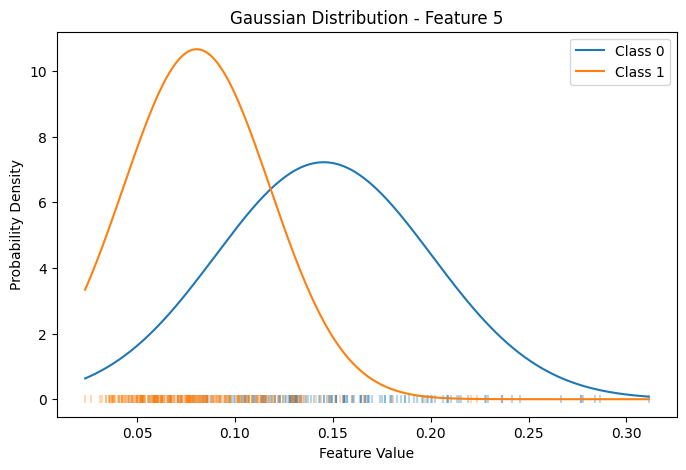

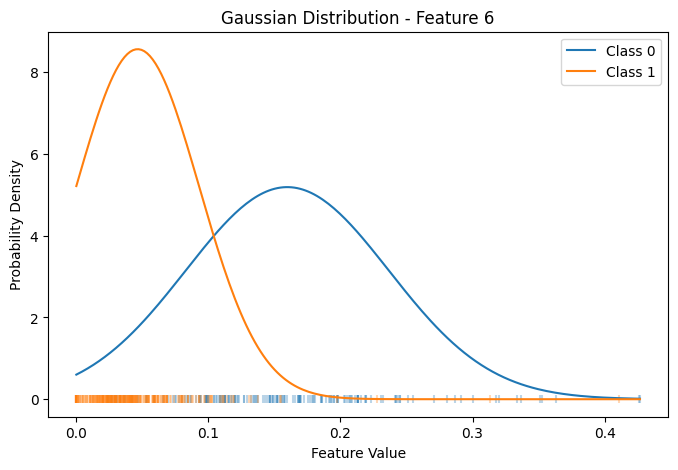

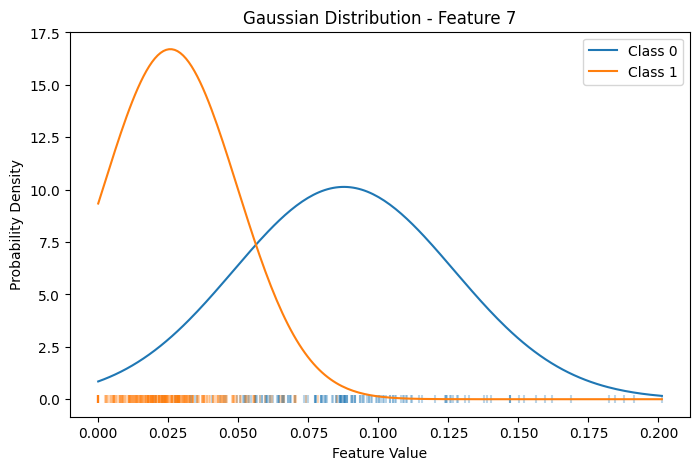

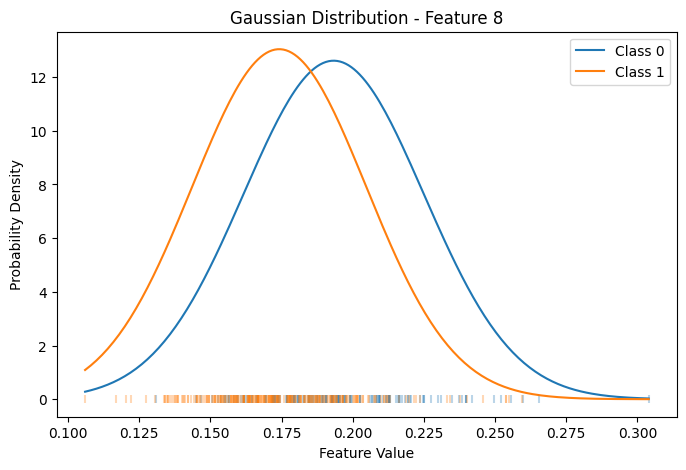

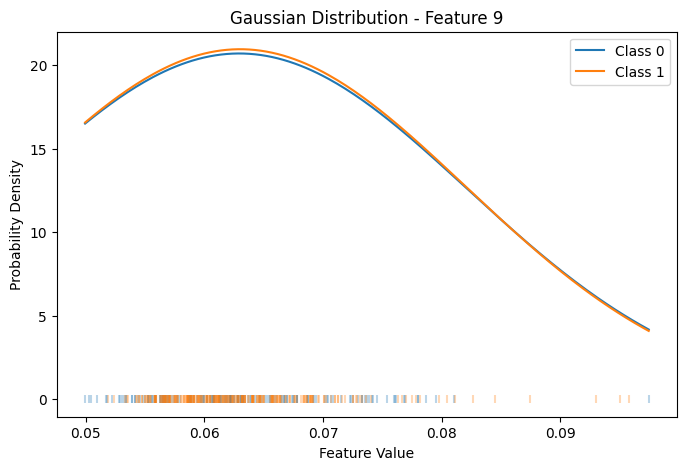

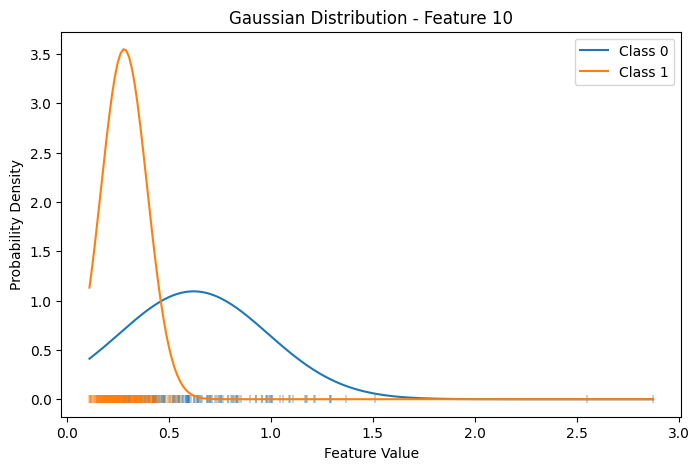

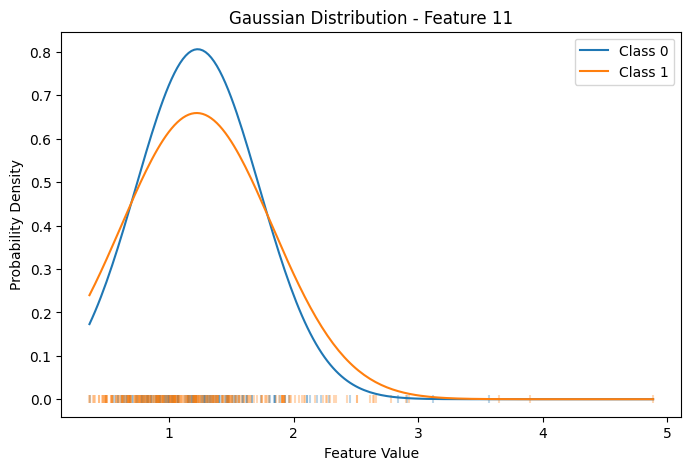

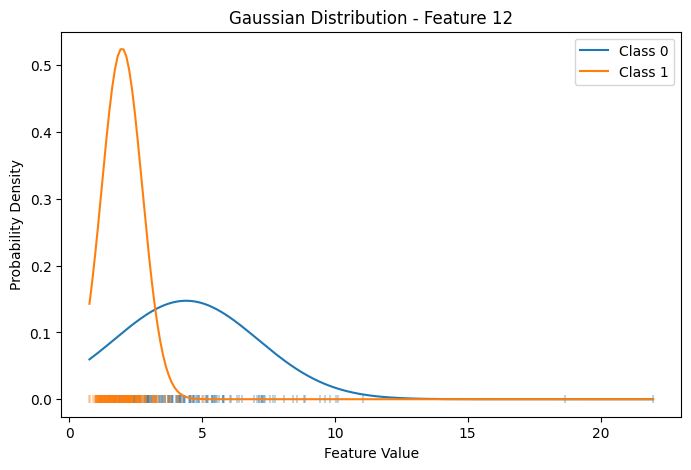

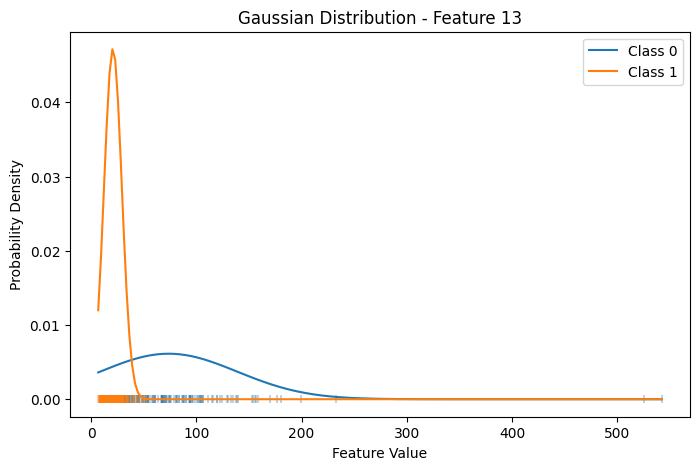

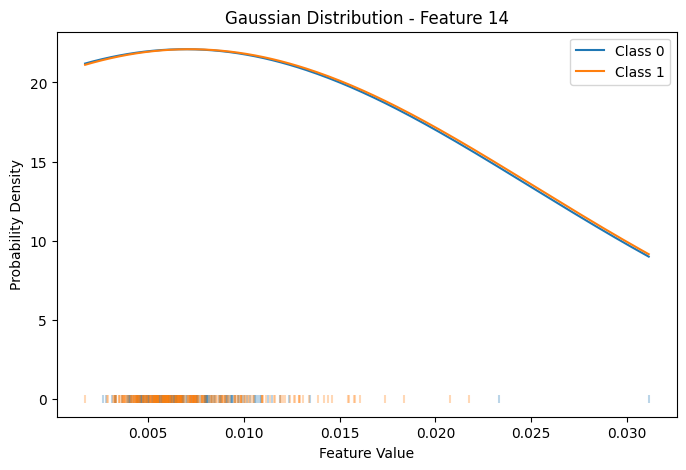

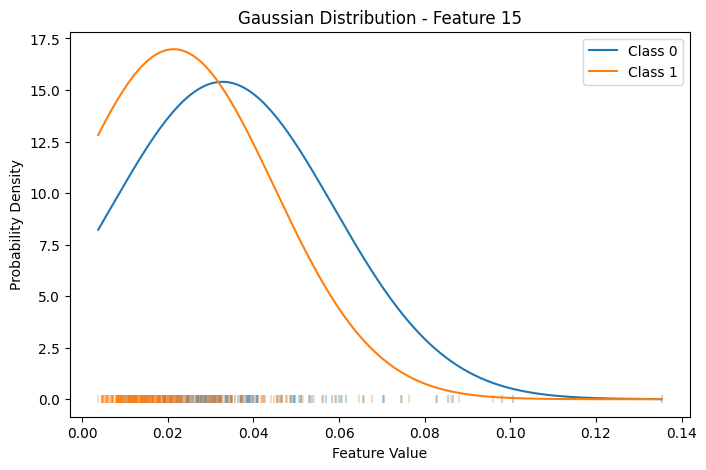

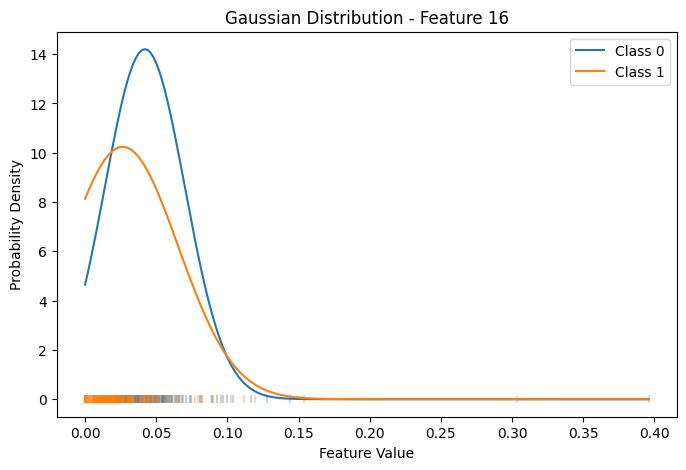

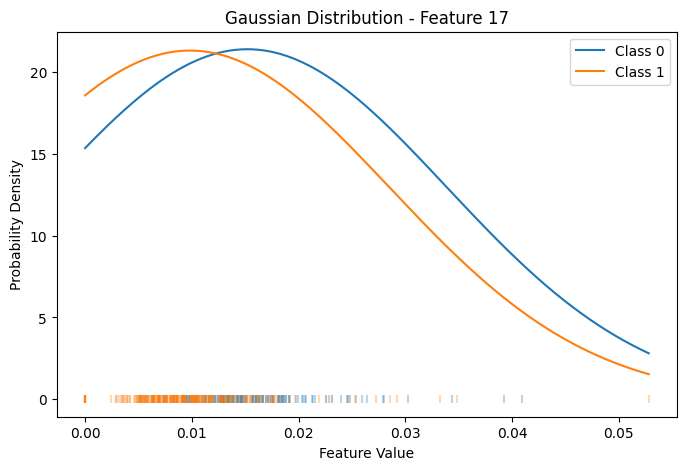

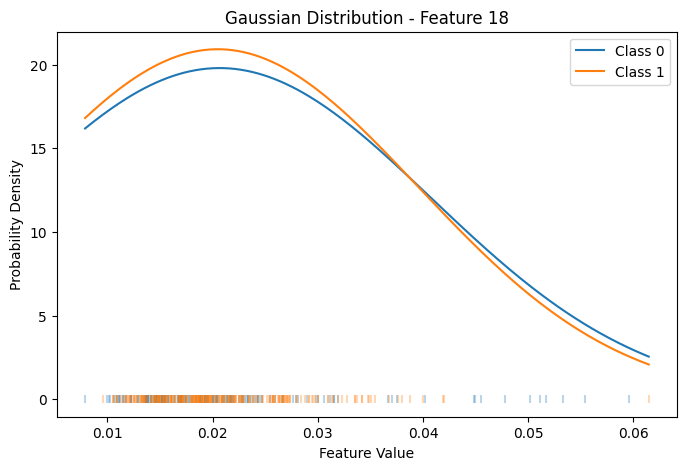

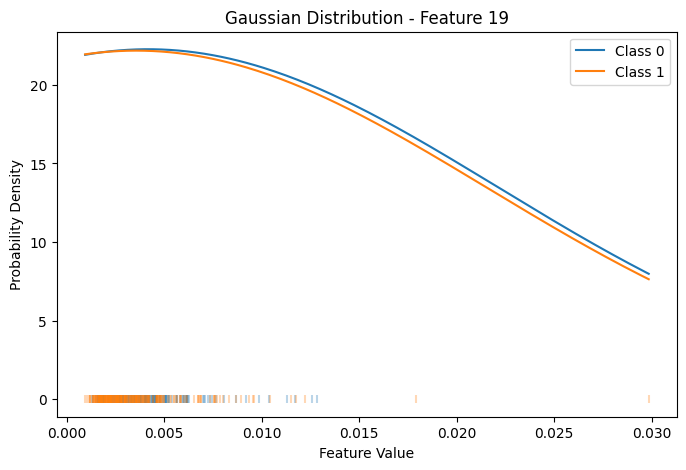

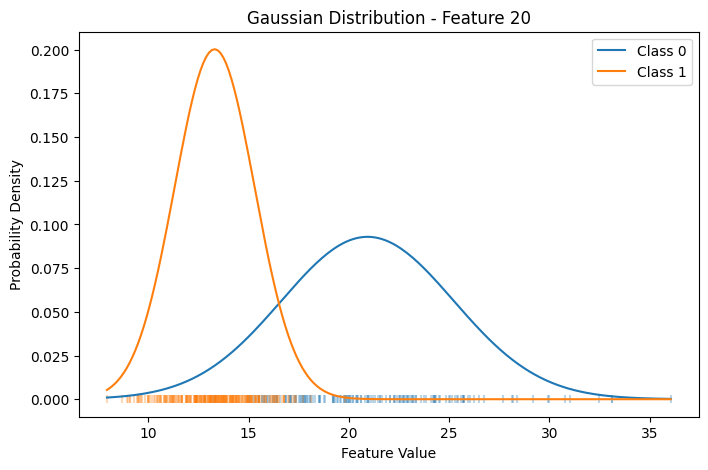

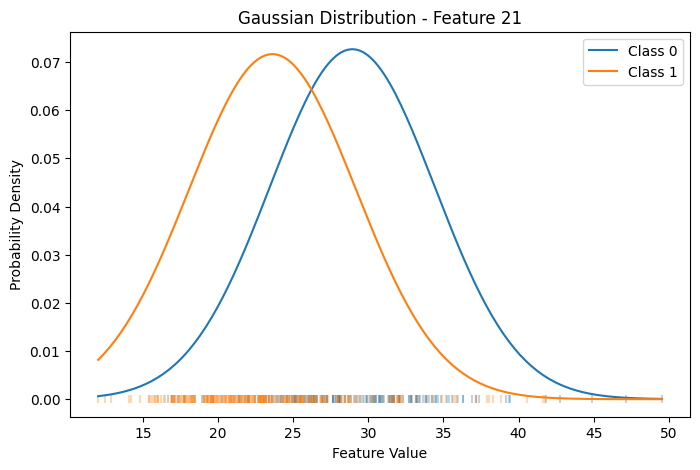

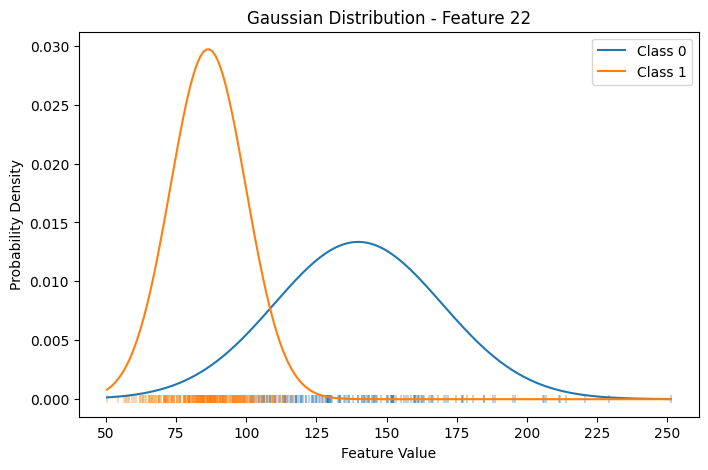

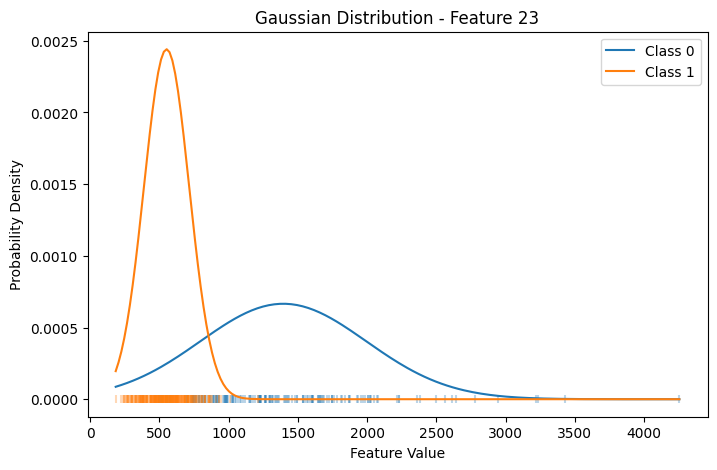

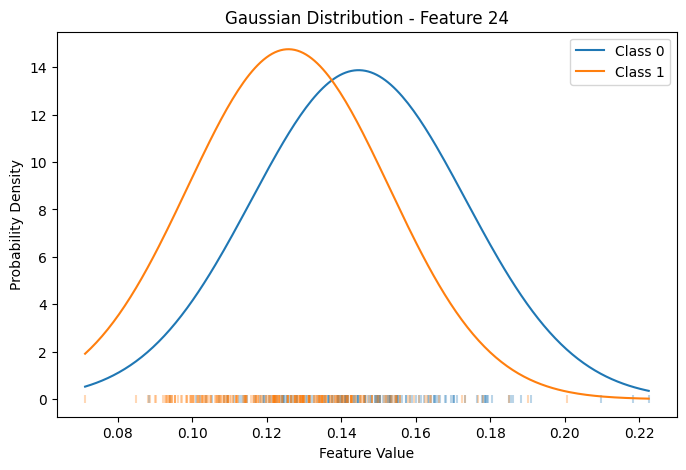

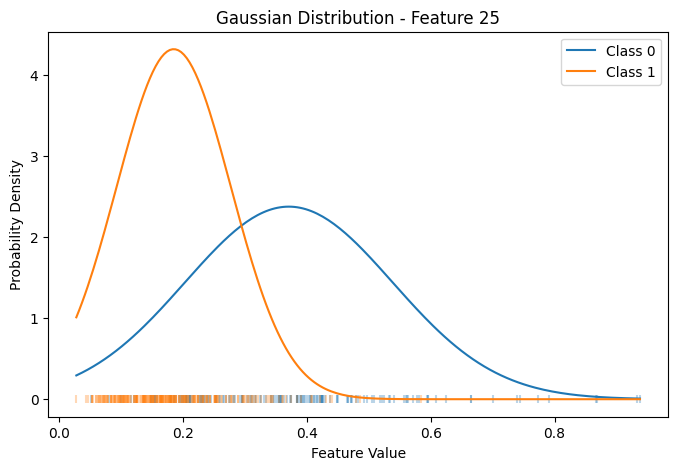

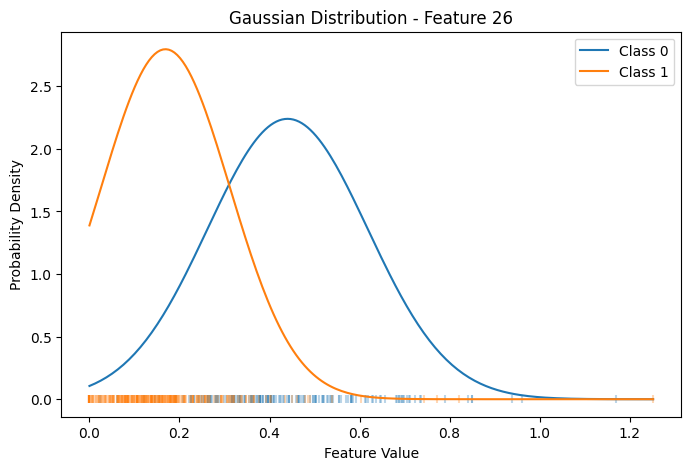

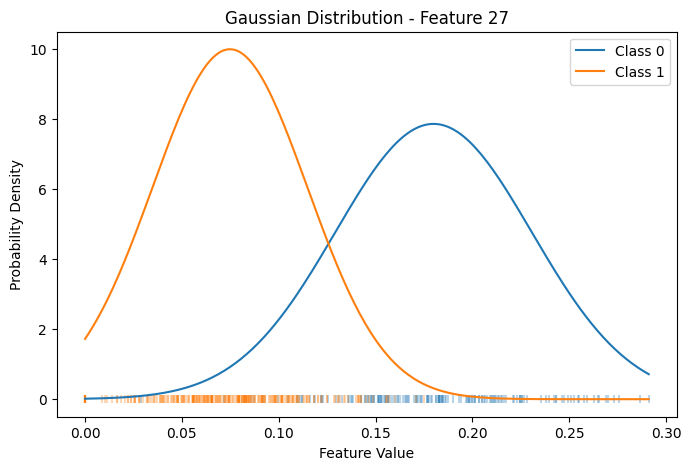

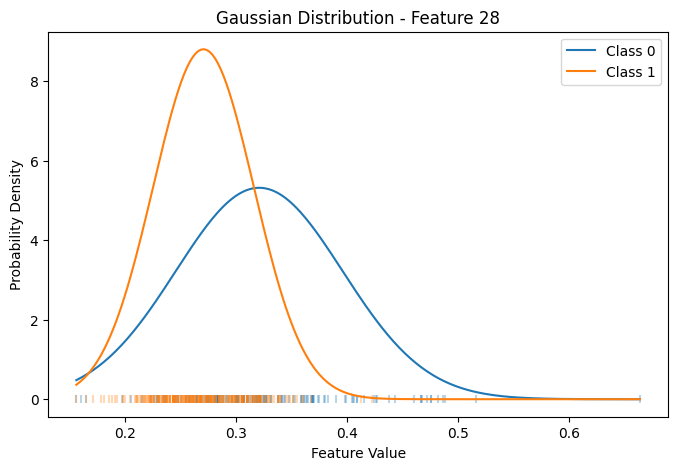

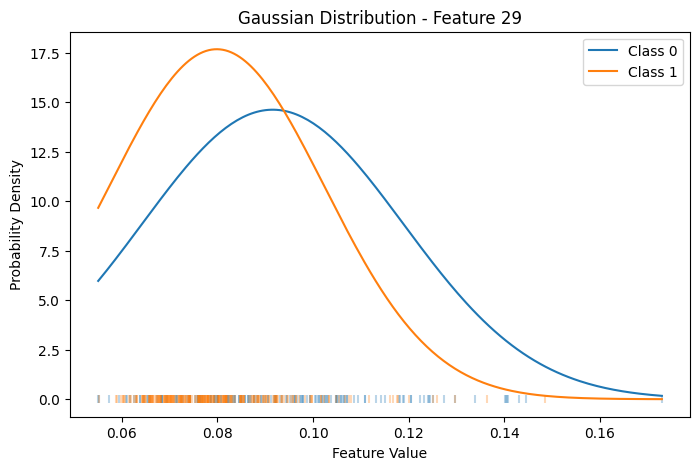

In [35]:
for feature_index in range(X_train.shape[1]):
    plt.figure(figsize=(8,5))
    for class_index, cl in enumerate(gnb_model.classes):
        mean= gnb_model.theta[class_index, feature_index]
        variance= gnb_model.var[class_index, feature_index]
        
        x_values = np.linspace(X_train[:, feature_index].min(), X_train[:, feature_index].max(),200)
        
        gaussian=(1/ np.sqrt(2 * np.pi * variance)) * np.exp(-((x_values - mean) ** 2) / (2 * variance))
        plt.plot(x_values, gaussian, label=f"Class {cl}")
        class_data = X_train[y_train == cl, feature_index]
        plt.scatter(class_data, np.zeros(len(class_data)), alpha=0.3, marker="|")
    plt.title(f"Gaussian Distribution - Feature {feature_index}")
    plt.xlabel("Feature Value")
    plt.ylabel("Probability Density")
    plt.legend()
    plt.show()

---
**5.2-Decision Regions**

In [36]:
X_train_2d= X_train[:,[0,1]]
X_test_2d= X_test[:,[0,1]]

In [37]:
print(X_train_2d.shape)
print(X_test_2d.shape)

(456, 2)
(113, 2)


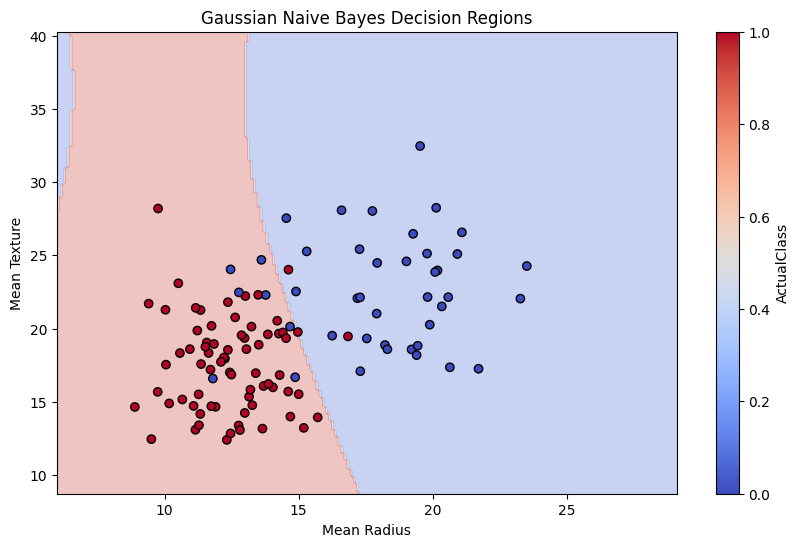

In [44]:
decision_model = GNBayes()
decision_model.fit(X_train_2d, y_train)

x_min = X_train_2d[:, 0].min() - 1
x_max = X_train_2d[:, 0].max() + 1
y_min = X_train_2d[:, 1].min() - 1
y_max = X_train_2d[:, 1].max() + 1

xx,yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                    np.linspace(y_min, y_max, 200))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = decision_model.predict(grid_points)
Z = Z.reshape(xx.shape)


plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(X_test_2d[:,0], X_test_2d[:,1], c=y_test, edgecolors="black",cmap="coolwarm")


plt.title("Gaussian Naive Bayes Decision Regions")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.colorbar(label="ActualClass")
plt.show()